# Metamodel case generation (LHS propagation)

Workflow:

1. Load **goals** from `Samoa.json` → `simulations.goals_file`.
2. Generate **Latin Hypercube** cases per goal (`tp`, `wd`, `ds`, `zs`).
3. Build SnapWave case directories from `templates-metamodel`.
4. Run cases (optional) and postprocess to per-goal NetCDF files.

Paths and bounds come from `Samoa.json` → `simulations`.

In [2]:
from utils.simulation import lhs_cases as sim
from utils.config import PATHS, SIMULATIONS, goals_for_snapwave, load_goals, resolve
from utils.simulation.snapwave_wrappers import SnapWaveMetaModelWrapper


## Configuration

In [3]:
templates_dir = resolve(SIMULATIONS["metamodel_templates"])
cases_dir = resolve(SIMULATIONS["metamodel_cases"])
aoi_file = resolve(PATHS["aoi_file"])
mesh_file = resolve(PATHS["mesh_file"])
goals_file = resolve(SIMULATIONS["goals_file"])

print(f"goals     : {goals_file}")
print(f"templates : {templates_dir}")
print(f"cases     : {cases_dir}")
print(f"mesh      : {mesh_file}")
print(f"samples   : {SIMULATIONS['num_samples_per_goal']} per goal")

goals     : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/goals/Samoa_goals.json
templates : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/templates-metamodel
cases     : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/SnapWave_CASES_Metamodel
mesh      : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/GRID/Samoa_mesh.nc
samples   : 500 per goal


## LHS cases

In [4]:
raw_goals = load_goals()

cases_df = sim.generate_cases(raw_goals)
cases_df["goal"] = cases_df["goal"].astype(int)
cases_df.head()

,goal,tp,dir,spr,wl
0,1,12.213669,353.854916,18.939314,1.302719
1,1,8.383269,354.075270,13.775162,-2.609729
2,1,6.444611,318.474843,13.077691,0.370466
3,1,5.190768,260.579408,42.685319,3.339651
4,1,7.184247,48.587851,21.310096,2.068328


<Axes: xlabel='tp', ylabel='dir'>

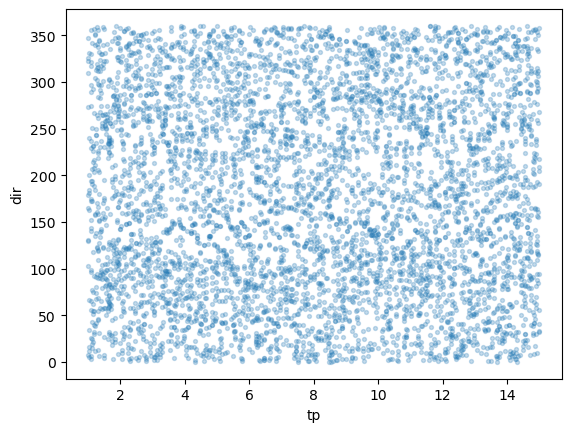

In [5]:
cases_df.plot.scatter(x="tp", y="dir", alpha=0.25, s=8)

## SnapWave wrapper

In [6]:
wrapper = SnapWaveMetaModelWrapper(
    templates_dir=str(templates_dir),
    metamodel_parameters=cases_df.to_dict(orient="list"),
    fixed_parameters={"gridfile": str(mesh_file)},
    output_dir=str(cases_dir),
    aoi_file=str(aoi_file),
    goals_config=goals_for_snapwave(raw_goals),
)
wrapper

2026-06-30 23:09:48,461 - SnapWaveMetaModelWrapper - WARNING - Parameter goal is not in the default_parameters
2026-06-30 23:09:48,461 - SnapWaveMetaModelWrapper - WARNING - Parameter tp is not in the default_parameters
2026-06-30 23:09:48,462 - SnapWaveMetaModelWrapper - WARNING - Parameter dir is not in the default_parameters
2026-06-30 23:09:48,462 - SnapWaveMetaModelWrapper - WARNING - Parameter spr is not in the default_parameters
2026-06-30 23:09:48,463 - SnapWaveMetaModelWrapper - WARNING - Parameter wl is not in the default_parameters


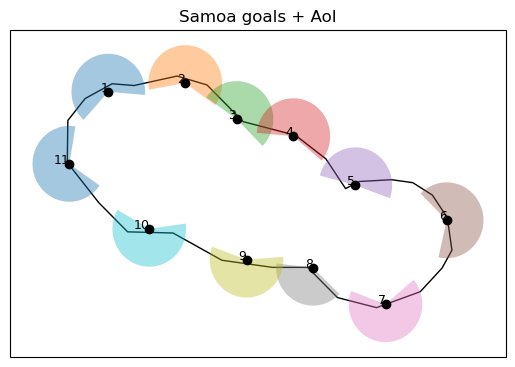

In [7]:
wrapper.plot_configuration()

In [8]:
wrapper.output_sites_df

,lon,lat,source,source_id,source_label,depth,name
0,-172.362339,-13.433536,isobath,5m_0,5m,-5.000000,NaN
1,-172.289348,-13.487306,isobath,5m_1,5m,-5.000000,NaN
2,-172.231790,-13.557491,isobath,5m_2,5m,-5.000000,NaN
3,-172.185137,-13.635869,isobath,5m_3,5m,-5.000000,NaN
4,-172.186410,-13.687549,isobath,5m_4,5m,-5.000000,NaN
...,...,...,...,...,...,...,...
626,-171.800626,-13.805272,mesh,Apia_14485,Apia,-0.774590,NaN
627,-171.727406,-13.840364,mesh,Apia_14531,Apia,-0.717097,NaN
628,-172.200000,-13.880000,buoy,buoy_Apolima_Buoy,waves,-80.000000,Savaii - Upolu middle buoy
629,-170.493000,-14.265000,buoy,buoy_American_Samoa_Buoy,waves,-75.000000,Ameican Samoa east buoy (Period 1)


## Build, run, postprocess

In [9]:
wrapper.build_cases(
    cases_name_format=lambda ctx: f"{ctx.get('goal'):02}/{ctx.get('case_num'):04}"
)

In [10]:
wrapper.run_cases_in_background(launcher="default", num_workers=2)

In [48]:
wrapper.monitor_cases(value_counts="simple")

Status  
FINISHED    5500
Name: count, dtype: int64

In [49]:
wrapper.postprocess_cases()

'Done'